<a href="https://colab.research.google.com/github/Business-Intelligence-Book/business-intelligence-book.github.io/blob/main/labs/03-visualization/walkthrough/walkthrough.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<h1 style="color:#2F5597"><span style="background:#2F5597;color:#fff;padding:2px 10px;border-radius:3px">Lab 03</span>&nbsp; Data visualization</h1>

<p style="color:#595959"><b style="color:#C55A11">Walkthrough</b> · Data visualization · <i>Business Intelligence and Analytics</i> · Chapter 4</p>

<div style="background:#FFF2CC;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#C55A11">💡 What you will learn this week</b></p>
<ul style="margin:0">
<li>How to choose the right chart for a question: histogram, boxplot, pie chart, scatter plot, line plot or heatmap</li>
<li>How to build static charts with matplotlib and seaborn</li>
<li>How to build interactive charts with ipywidgets and plotly</li>
<li>How to apply the guidelines for clear and honest charts</li>
</ul>
</div>

Run the cells from top to bottom. Text cells explain each step; code cells show how to do it in Python.

---

This walkthrough introduces the main visualization tools and shows how to present and interpret data in charts. There are many ways to represent data, so we also show typical examples of the right chart for a given question.

The first part covers static charts: some that you met in the previous lab, and some new ones.

The second part goes further and shows how to build interactive visualizations.

<div style="background:#E8EEF7;border-radius:10px;padding:14px 20px;margin:12px 0;color:#222">
<p style="margin:0 0 6px 0"><b style="color:#2F5597">⭐ Fun fact: Four datasets, the same statistics</b></p>
In 1973 the statistician Francis Anscombe built four small datasets that have almost exactly the same means, variances, correlation and regression line. When plotted, they look completely different: one is a line with noise, one a curve, one a line with a single outlier, and one a vertical stack of points with one point far away. Anscombe's quartet is still the classic argument for plotting your data before you trust a summary.
</div>

## Imports and dataset
First, let's import the libraries we need.

We use [`matplotlib`](https://matplotlib.org/stable/index.html), a library for plotting, and [`seaborn`](https://seaborn.pydata.org), a package for statistical data visualization.

In [1]:
# Library imports
import pandas as pd  # nothing new here
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

We use the **Credit.csv** dataset, which contains personal and financial information about credit card holders.

In [2]:
url = "https://raw.githubusercontent.com/Business-Intelligence-Book/business-intelligence-book.github.io/main/labs/data/Credit.csv"
data = pd.read_csv(url)
data.head()

,Unnamed: 0,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
0,1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
1,2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
2,3,104.593,7075,514,4,71,11,Male,No,No,Asian,580
3,4,148.924,9504,681,3,36,11,Female,No,No,Asian,964
4,5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


### Data cleaning
An "Unnamed: 0" column is not very helpful. Let's rename it.

In [3]:
data = data.rename(columns={"Unnamed: 0": "CustomerID"})
# data = data.set_index('CustomerID')
data.head()

,CustomerID,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
0,1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
1,2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
2,3,104.593,7075,514,4,71,11,Male,No,No,Asian,580
3,4,148.924,9504,681,3,36,11,Female,No,No,Asian,964
4,5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


In [4]:
summary = data.describe()
summary.round(2)

,CustomerID,Income,Limit,Rating,Cards,Age,Education,Balance
count,400.00,400.00,400.00,400.00,400.00,400.00,400.00,400.00
mean,200.50,45.22,4735.60,354.94,2.96,55.67,13.45,520.02
std,115.61,35.24,2308.20,154.72,1.37,17.25,3.13,459.76
min,1.00,10.35,855.00,93.00,1.00,23.00,5.00,0.00
25%,100.75,21.01,3088.00,247.25,2.00,41.75,11.00,68.75
50%,200.50,33.12,4622.50,344.00,3.00,56.00,14.00,459.50
75%,300.25,57.47,5872.75,437.25,4.00,70.00,16.00,863.00
max,400.00,186.63,13913.00,982.00,9.00,98.00,20.00,1999.00


As in the previous labs, we check the type of each column before going further. Let's get an overview of the dataset to know what to expect.

In [5]:
# get information from data frame
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   CustomerID  400 non-null    int64  
 1   Income      400 non-null    float64
 2   Limit       400 non-null    int64  
 3   Rating      400 non-null    int64  
 4   Cards       400 non-null    int64  
 5   Age         400 non-null    int64  
 6   Education   400 non-null    int64  
 7   Gender      400 non-null    object 
 8   Student     400 non-null    object 
 9   Married     400 non-null    object 
 10  Ethnicity   400 non-null    object 
 11  Balance     400 non-null    int64  
dtypes: float64(1), int64(7), object(4)
memory usage: 37.6+ KB


Now let's begin with the visualization. Throughout this lab, we apply the main guidelines for a successful visualization presented in chapter 4 of the book.

As a refresher:<br>
**1. Keep it simple**<br>
**2. Design and choose the visualization well**<br>
**3. Know your audience, tell a story**<br>
**4. Have graphical integrity**

# Static visualizations

## Boxplots

A boxplot is a must when you need a statistical overview of numerical data. It shows:

- the median
- the quartiles (1st and 3rd)
- the minimum
- the maximum
- the outliers

For instance, suppose we investigate the **income distribution**. A boxplot of the income helps to identify the outliers.

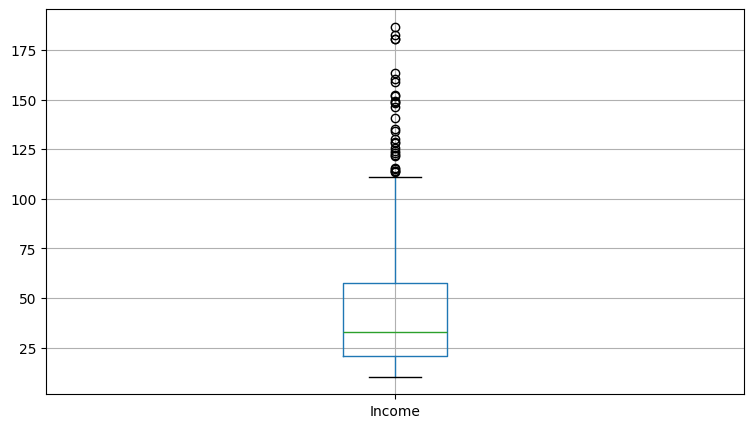

In [6]:
# using figure size to increase the window
fig = plt.figure(figsize=(9, 5))
box_plot = data.boxplot(column="Income")

Seaborn can compare distributions across categories. With the `hue` parameter, it draws the boxplots of several groups side by side.

For instance, we can compare the income distribution across ethnicities and genders. This chart helps to:
- compare the spread of income between groups
- identify differences in the median across categories
- highlight variations and potential outliers within groups

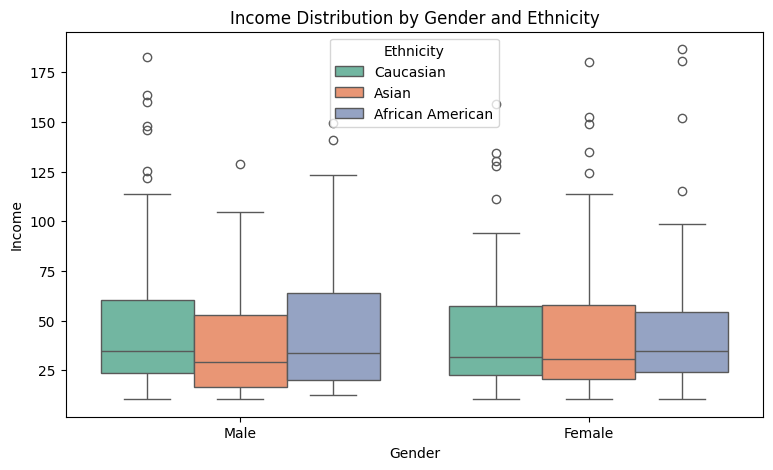

In [7]:
fig, ax = plt.subplots(figsize=(9, 5))
graph = sns.boxplot(
    y="Income", hue="Ethnicity", x="Gender", data=data, ax=ax, palette="Set2"
)
graph.set_xlabel("Gender")
graph.set_ylabel("Income")
ax.set_title("Income Distribution by Gender and Ethnicity")
plt.show();

## Bar plot and histogram

Now let's look at the number of credit card holders per gender. A bar chart gives a quick answer.

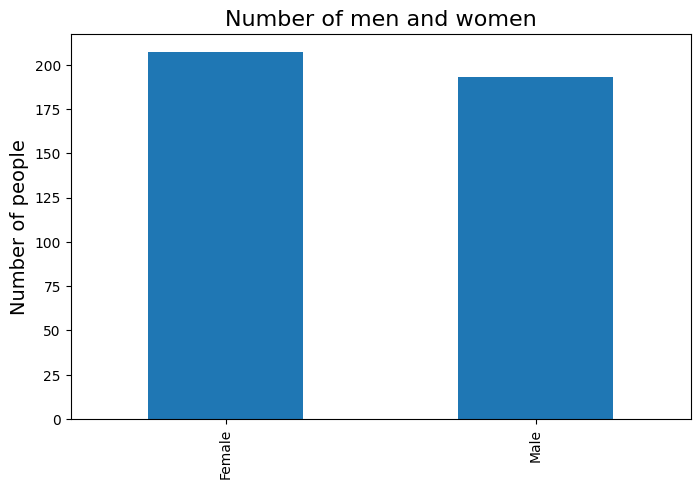

In [8]:
data_bar = data["Gender"].value_counts()
fig = plt.figure(figsize=(8, 5))

graph = data_bar.plot(kind="bar")

# It is possible to add many details to a graph by using simple commands. eg.
graph.set_title("Number of men and women", size=16)
graph.set_xlabel("")
txt = graph.set_ylabel("Number of people", size=14)

The bars can also be horizontal, by setting the kind of plot to `barh`.

Text(0.5, 0, 'Number of people')

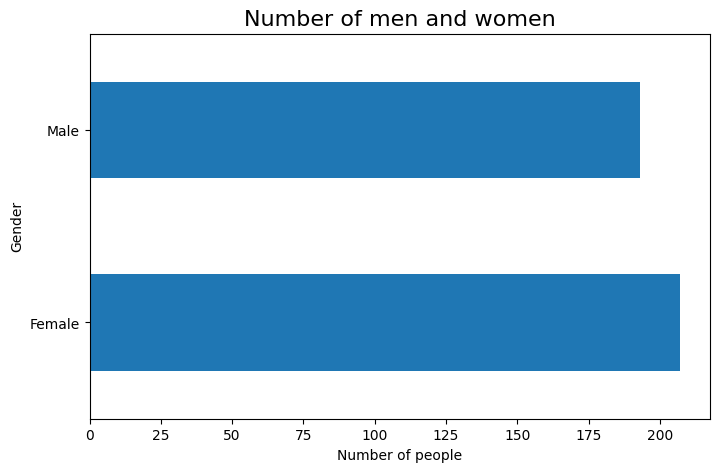

In [9]:
fig = plt.figure(figsize=(8, 5))

data_bar = data["Gender"].value_counts()
graph = data_bar.plot(kind="barh")
graph.set_title("Number of men and women", size=16)
graph.set_xlabel("Number of people", size=10)

Keep in mind that granularity (how much data is shown on the chart) plays an important role in a visualization.
Let's take the example of the distribution of the average income per age.

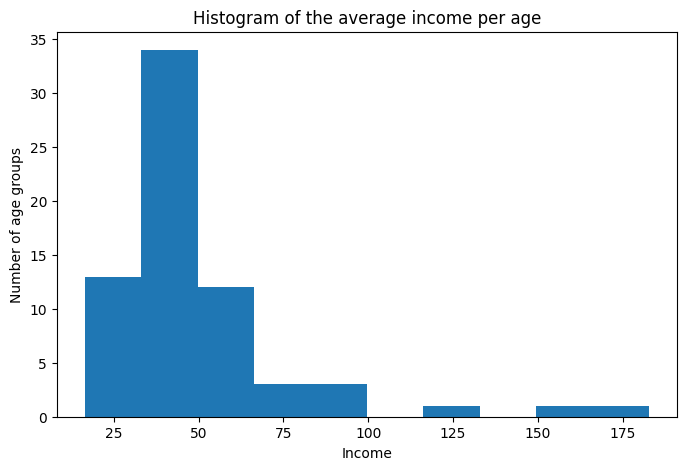

In [10]:
fig = plt.figure(figsize=(8, 5))

hist = plt.hist(data.groupby("Age")["Income"].mean())
plt.title("Histogram of the average income per age")
plt.xlabel("Income")
y = plt.ylabel("Number of age groups")

Can you think of another kind of chart to visualize proportions?

## Pie chart
Let's look at the proportion of students in the customer base.

Text(0.5, 1.0, 'Proportion of customers that are students')

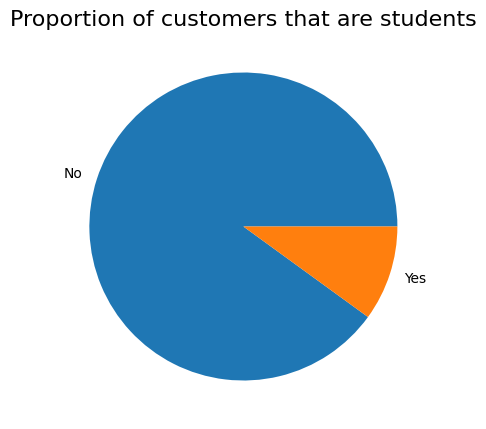

In [11]:
data_pie = data["Student"].value_counts()
labels = data[
    "Student"
].unique()  # get the unique values that can take this column of our dataframe
labels = labels.tolist()  # and make it a list in order to label our further piechart
fig = plt.figure(figsize=(9, 5))

graph = plt.pie(data_pie, labels=labels)  # you can add as many parameters as you wish
plt.title("Proportion of customers that are students", size=16)

## Line plots and scatter plots

### 1. Line plot

A line plot shows how one value evolves as a function of another variable. Here we show how `Income` evolves with `Age`.

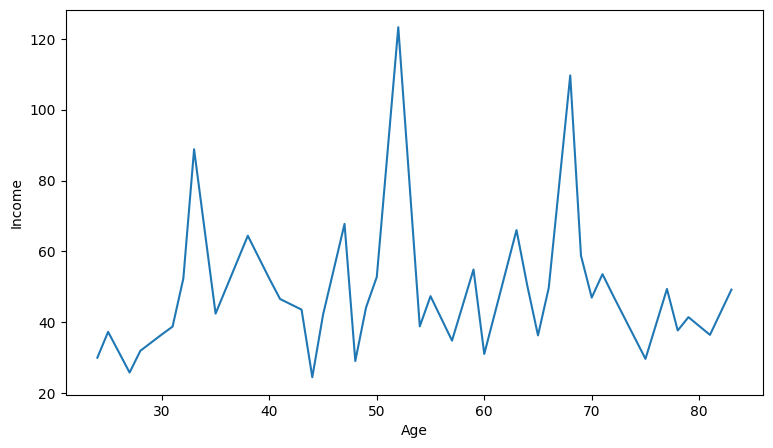

In [12]:
fig = plt.figure(figsize=(9, 5))
sb = sns.lineplot(
    x=data["Age"], y=data.groupby("Age")["Income"].mean(), errorbar=None
)  # We specify 'None' to not have the 95% ci plotted too but you can try to display it

We can also select a category of people. For example, here is the income by age for married people (for more options, see the [seaborn documentation](https://seaborn.pydata.org/generated/seaborn.lineplot.html)):

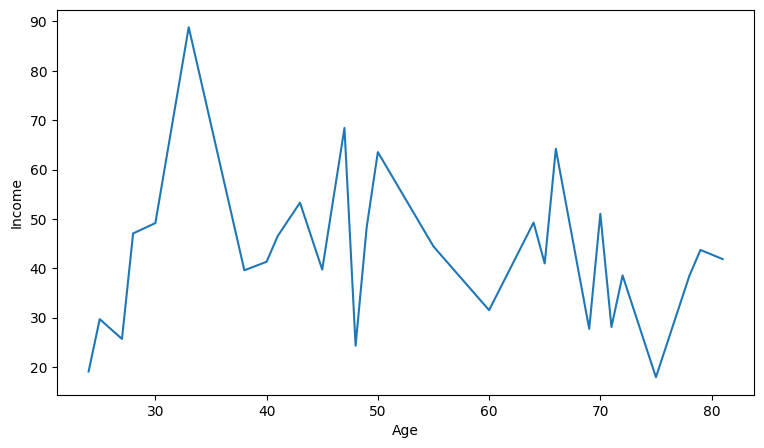

In [13]:
fig = plt.figure(figsize=(9, 5))
income_active = data.query("Married == 'Yes'")
sb = sns.lineplot(
    data=income_active,
    x="Age",
    y=income_active.groupby("Age")["Income"].mean(),
    errorbar=None,
)

### 2. Scatter plot

A scatter plot is very useful to see whether two variables are correlated. Let's check whether the credit card limit is correlated with the income.

You can add a reference line with **plt.plot**.

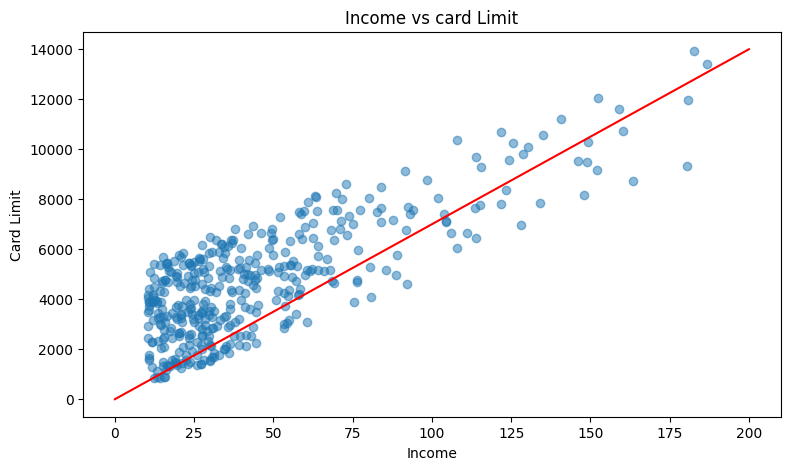

In [14]:
fig = plt.figure(figsize=(9, 5))
plt.scatter(
    data["Income"], data["Limit"], alpha=(1 / 2)
)  # alpha sets the transparency of the points
plot = plt.plot([0, 200], [0, 14000], color="red")
plt.title("Income vs card Limit")
plt.xlabel("Income")
y = plt.ylabel("Card Limit")

## Heatmaps

A heatmap shows the Pearson correlation coefficients at a glance, with a color map that you can change to your taste.

Let's create a heatmap of the **correlations** between the columns `Limit`, `Income`, `Age` and `Rating`.

Text(0.5, 1.0, 'Heatmap of correlations between dataset features')

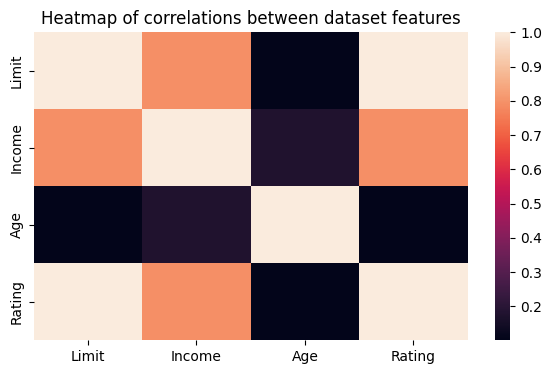

In [15]:
fig = plt.figure(figsize=(7, 4))

heat_map = data[
    ["Limit", "Income", "Age", "Rating"]
].corr()  # We must add .corr() here as we are looking for the correlations between our variables.
sb = sns.heatmap(data=heat_map)
plt.title("Heatmap of correlations between dataset features")

# Interactive visualization

## Ipywidgets
In this second part, we move to interactive charts. We start with widgets, which make a notebook come alive: they let you change a value and see the effect immediately.

In [16]:
!pip install ipywidgets --upgrade

In [17]:
import ipywidgets as widgets
from ipywidgets import interact, interact_manual

In [18]:
from __future__ import print_function
from ipywidgets import interact, interactive, fixed, interact_manual
import ipywidgets as widgets

In this example, we compute the total amount of a loan from the **loan amount**, the **interest rate** and the number of **years** until the end of the loan.

In [19]:
def total_amount(amount, rate, years):
    return amount * pow((1 + rate), years)

In [20]:
interact(
    total_amount,
    amount=widgets.IntSlider(min=10, max=300, description="Initial Amount"),
    rate=widgets.FloatSlider(min=0, max=1, step=0.01, description="Interest Rate"),
    years=widgets.IntSlider(min=1, max=20, description="Term (years)"),
)
print(total_amount)

interactive(children=(IntSlider(value=10, description='Initial Amount', max=300, min=10), FloatSlider(value=0.…

<function total_amount at 0x7f1f50a15620>


We can also create an interactive plot by combining ipywidgets and matplotlib. For that, we put the plotting code inside the `total_amount` function. We get the same sliders as before, but now the chart shows the amount owed over time.

In [21]:
import numpy as np

fig = plt.figure(figsize=(10, 5))


def total_amount(amount, rate, years):
    time = np.arange(1, years + 1)
    amount_reimbursed = [amount * pow((1 + rate), t) for t in time]
    plt.plot(time, amount_reimbursed)
    plt.xlabel("Time (years)")
    plt.ylabel("Amount Reimbursed")
    plt.title("Amount Reimbursed Over Time")
    plt.grid(True)
    plt.show()


amount_slider = widgets.IntSlider(min=10, max=300, description="Initial Amount")
rate_slider = widgets.FloatSlider(min=0, max=1, step=0.01, description="Interest Rate")
years_slider = widgets.IntSlider(min=1, max=20, description="Term (years)")

interact(total_amount, amount=amount_slider, rate=rate_slider, years=years_slider)

<Figure size 1000x500 with 0 Axes>

interactive(children=(IntSlider(value=10, description='Initial Amount', max=300, min=10), FloatSlider(value=0.…

<function __main__.total_amount(amount, rate, years)>

Colab offers another way to add sliders. Write **#@param** after a variable, or click on the three dots at the right of a cell and choose **Add a form**. <br>
See this [page](https://colab.research.google.com/notebooks/forms.ipynb) to learn more about this feature of Colab.

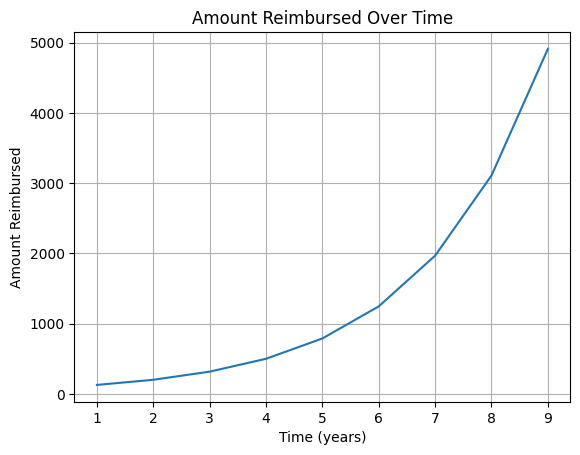

None


In [22]:
var_1 = 80  #@param {type:"slider", min:10, max:300, step:1}
var_2 = 0.58  #@param {type:"slider", min:0, max:1, step:0.01}
var_3 = 9  #@param {type:"slider", min:1, max:20, step:1}

print(total_amount(var_1, var_2, var_3))

Widgets can also work as filters. Let's go back to the **credit** dataset and suppose that we want to display only the rows that have a particular value in a categorical column.

We create a drop-down list with the distinct values of the column, and use it to control which rows are displayed. An "All" option displays all the rows.

Here we filter on the **gender** of the customers:

In [23]:
items = ["All"] + sorted(data["Gender"].unique().tolist())


def view(x=""):
    if x == "All":
        return data
    return data[data["Gender"] == x]


w = widgets.Select(options=items)
interact(view, x=w)

interactive(children=(Select(description='x', options=('All', 'Female', 'Male'), value='All'), Output()), _dom…

<function __main__.view(x='')>

## Folium
Sometimes we need to show locations on a map. Here is a way to do so.

In [24]:
!pip install folium --upgrade

In [25]:
import folium

df2 = pd.DataFrame(
    {
        "lat": [40.6892, 40.7484, 40.7829, 40.7061],
        "lon": [-74.0445, -73.9857, -73.9654, -73.9969],
        "name": [
            "Statue of Liberty",
            "Empire State Building",
            "Central Park",
            "Brooklyn Bridge",
        ],
        "value": [20, 50, 40, 30],
    }
)
# Create an empty map
v = folium.Map(location=[40.7350, -74.0000], zoom_start=11, width=1000, height=500)

# Add marker one by one on the map
for i in range(0, len(df2)):
    folium.Circle(
        location=[df2.iloc[i]["lat"], df2.iloc[i]["lon"]],
        popup=df2.iloc[i]["name"],
        radius=float(df2.iloc[i]["value"]) * 20,
        fill=True,
        fill_color="crimson",
    ).add_to(v)
# Show the map
display(v)

## Plotly

### Treemap

Finally, treemaps display hierarchical data as nested rectangles. Each level of the hierarchy is a layer, and the size of each rectangle corresponds to a numerical value. The chart is interactive: you can zoom in by clicking on a sector. Run the next cells and play with the treemap.

We use the [`plotly`](https://plotly.com) library, and specifically its `express` package.

In [26]:
# You will probably not need this, but run it in case of a 'path' error
!pip install plotly --upgrade

We go back to our dataset and use a treemap to visualize how income varies with marital status, student status, gender and ethnicity.

In [27]:
data.head()

,CustomerID,Income,Limit,Rating,Cards,Age,Education,Gender,Student,Married,Ethnicity,Balance
0,1,14.891,3606,283,2,34,11,Male,No,Yes,Caucasian,333
1,2,106.025,6645,483,3,82,15,Female,Yes,Yes,Asian,903
2,3,104.593,7075,514,4,71,11,Male,No,No,Asian,580
3,4,148.924,9504,681,3,36,11,Female,No,No,Asian,964
4,5,55.882,4897,357,2,68,16,Male,No,Yes,Caucasian,331


In this example, we create a treemap of the **average income** by ethnicity, gender, student status and marital status. We use `groupby()` to group the data by `Ethnicity`, `Gender`, `Student` and `Married`, and compute the average `Income` of each combination with `.mean()`.

`.reset_index()` keeps the grouped columns as regular columns of the DataFrame.

`df["all"] = "all"` creates a single root node at the top of the hierarchy, so that all categories belong to one structure.

`px.treemap()` generates the interactive treemap. The `path` parameter defines the levels of the hierarchy: `Ethnicity` → `Gender` → `Student` → `Married`.

If you hover over a rectangle, a tooltip shows the details of that group. For example, Caucasian females who are students and married have an average income of 36,271.

In [28]:
import plotly.express as px

df = (
    data.groupby(["Ethnicity", "Gender", "Student", "Married"])[["Income"]]
    .mean()
    .reset_index()
)

df["all"] = "all"  # in order to have a single root node
fig = px.treemap(
    df, path=["Ethnicity", "Gender", "Student", "Married"], values="Income"
)
fig.show()